# 数据与机器学习（Machine Learning），M2CHPS

## 第 1 次实验课

**授课教师：** [Argyris Kalogeratos](http://kalogeratos.com)（联系方式：argyris.kalogeratos@ens-paris-saclay.fr）。  
**课程大纲：** [http://nvayatis.perso.math.cnrs.fr/CHPScourse.html](http://nvayatis.perso.math.cnrs.fr/CHPScourse.html)

本文件的最新版本可在教师的个人网页上找到：  
[http://kalogeratos.com/psite/files/MyCourses/DML-M2HPC/Lab#.ipynb](http://kalogeratos.com/psite/files/MyCourses/DML-M2HPC/Lab#.ipynb)。
其中，`#` 应替换为实验课的编号。这些 Notebook 内容自成一体，包含所需的其他资源链接。

部分 scikit-learn 教学内容来自其[在线文档与教程](https://scikit-learn.org/stable/modules/linear_model.html)。

> 翻译进度：已完成全部 13 章。英文原文件保留不变。


<!-- classroom:intro -->

### 课堂补充｜这门“实验课”希望你学到什么

老师说明，课程虽然叫 lab，但形式是讲解、代码演示和动手练习结合：既回顾前面学过的概念，也补充理解这些概念所需的例子。文件编号不一定与每次上课一一对应；Lab0 是 Python、Git 等准备材料。

课程会反复回到基础问题：模型作了什么假设？它为什么给出这个答案？我们能否把结果拆成可检查的部分？只会调用工具，很容易在得到结果后再寻找一个“听起来合理”的解释，却不知道结果究竟是否成立。

老师用医学影像识别作类比：一个模型可以非常准确地识别异常，这种能力本身有价值；但如果人仍不知道它依据什么作出判断，预测能力的提高并不自动等于人对机制的理解加深。老师把自己的研究取向称为统计机器学习（Statistical Machine Learning）：除了性能，还关心结果的统计解释、适用条件与保证。这里是在说明本课的关注点，不是在否定高性能模型的价值。

> 阅读说明：“课堂补充”是根据转录整理的中文讲解，不是逐字引语。来源不含录音时间戳，以下用文件与行号定位。part2 与 part3 的公共部分只整理一次；专有名词首次出现时标注英文。

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 1—2 行；[transcript_part1.md](./transcript_part1.md)，第 25—61 行；[transcript_part1.md](./transcript_part1.md)，第 70—115 行。*

<!-- /classroom:intro -->



## 目录

1. [基本概念](#1.-Fundamental-concepts)
2. [简单线性回归](#2.-Simple-Linear-Regression)
3. [广义线性模型](#3.-Generalized-Linear-Models)
4. [Python 中的线性回归](#4.-Linear-Regression-in-Python)
5. [岭回归](#5.-Ridge-Regression)
6. [Lasso](#6.-Lasso)
7. [弹性网](#7.-Elastic-net)
8. [优化中的正则化范数](#8.-Regularization-norms-in-optimization)
9. [稳健线性回归](#9.-Robust-Linear-Regression)
10. [普通线性回归与逻辑回归的拟合](#10.-Fitting-Ordinary-Linear-Regression-and-Logistic-Regression)
11. [欠拟合与过拟合：多项式回归示例](#11.-Underfitting-vs-Overfitting:-Example-in-Polynomial-Regression)
12. [偏差与方差的权衡](#12.-Bias-vs-Variance-trade-off)
13. [验证方法](#13.-Validation-techniques)


<a id="1.-Fundamental-concepts"></a>

## 1. 基本概念

**数据（Data）**

数据是关于我们想要解决的问题的信息。通常，数据由一组样本（Examples）或数据对象（Data Objects）组成，记作 $X=\{x_i\}_{i=1}^n$，其中每个对象由一组特征（Features，也称变量 Variables）描述。每个对象都属于某个数据空间，这个空间也称为输入数据的*定义域（Domain）*。例如，若对 $\forall i$ 都有 $x_i \in \mathbb{R}^d$，那么这里的定义域就是 $d$ 维实数空间。如果问题属于监督学习（Supervised Learning），那么对于每个数据对象 $x_i$，数据中还应提供期望的输出 $y_i$（目标变量，Target Variable）。



<!-- classroom:data_variables -->

### 课堂补充｜同一个特征，为什么又叫“变量”？

看单个对象时，身高、颜色等是它的特征，记录下来的值已经确定。换成统计视角，把这个对象看作从某个总体分布（Distribution）中抽取的样本，同一特征在不同对象上会取不同值，这时就把它作为随机变量来研究。“特征”和“变量”反映的是观察角度的变化，并不是数据忽然变成了另一种东西。

监督学习中的标签（Label）表达的是“对这个输入，希望系统给出什么回答”。例如，给动物照片标上猫或狗，是为了训练系统回答猫狗分类问题；这些标签并不会自动帮助系统回答与这个任务无关的问题。无监督学习（Unsupervised Learning）则没有提供这种期望答案，算法只能依据输入数据本身寻找结构。

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 118—136 行。*

<!-- /classroom:data_variables -->

**模型（Model）与参数（Parameters）**

模型 $\mathcal{M}$ 用数学形式描述输入数据如何产生输出或决策。简单来说，模型就是一个*函数（Function）*。模型可以带有一组参数 $\Theta = \{\theta_1, \theta_2,...\}$，以便灵活地描述不同情况。我们可以将带参数的模型写作 $\mathcal{M}_\Theta$。任何模型 $\mathcal{M}_\Theta$ 都可以看作某个模型类（Model Class）中的一个成员，即 $\mathcal{M}_\Theta \in \mathcal{C}$。例如，如果 $\mathcal{M}_\Theta$ 是线性模型（Linear Model），那么 $\mathcal{C}$ 可以是所有线性模型组成的类，也就是让参数 $\Theta$ 遍历所有可能取值时得到的模型集合。



<!-- classroom:model_class -->

### 课堂补充｜选模型与调参数是两件事

老师把模型类看作“允许答案落入的范围”。如果选择直线模型，斜率和截距提供了移动、旋转直线的自由；把这些参数取遍，得到的仍然只是直线。训练可以在这个范围里找到更合适的直线，却不会自己把直线变成曲线。

因此，“拟合不好”可能有不同原因：参数还没有调好，也可能是模型类本身不适合问题。如果真实关系明显弯曲，从直线改用多项式，是扩大或改变候选模型的范围；这与固定一个线性模型后优化参数不同。

**课堂问答：优化的是模型，还是数据？** 固定模型形式后，通常优化的是它的参数，数据用来衡量这些参数的好坏。更广义的学习过程还可以包括比较不同模型或神经网络架构；但对每个选定的架构，仍然需要单独训练其参数。

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 136—178 行。*

<!-- /classroom:model_class -->

**优化问题（Optimization Problem）与目标函数（Objective Function）**

机器学习的基本做法是：先针对给定问题定义一个模型 $\mathcal{M}_\Theta$，再定义一个目标函数，用来衡量具有某组给定参数值的模型解决该问题的效果。目标函数既可以表示负面因素（例如代价 Cost），也可以表示正面因素（例如性能 Performance 或似然 Likelihood）。最后，建立一个优化问题，通过优化所选的目标函数来学习模型参数 $\Theta$。

*这就是“学习”的含义！*


<!-- classroom:fit_not_general -->

### 课堂补充｜对当前样本拟合得好，还不能说明什么？

“拟合得好”首先只是说：模型对这份数据的回答比较好。但这份数据只是现实中的一个样本；如果样本不具代表性，或者模型只贴合了它的细节，就不能据此断言模型在一般情况下也好。

老师因此要求同时理解问题与方法：实际问题决定哪些假设合理，方法的数学结构决定它能表达什么。后面讨论外推、过拟合和验证集，都是在继续回答这个问题：眼前数据上的好结果，能否支持我们对未知数据的期待？

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 178—193 行。*

<!-- /classroom:fit_not_general -->



### 将机器学习用于现实中的数据问题时，请始终记住：

**a）现实可能与理论不同，也可能难以处理**

* 每种方法都有自己的假设和关注点。实际环境越接近某种方法所设想的情形，例如没有违反该方法的假设，这种方法就越有可能取得较好的效果。请确保自己充分理解正在处理的问题，以及选择使用的方法。

***b）如何检验数据并从中提取价值？***

* 简短的回答是：这在一定程度上是一门艺术！



<!-- classroom:data_value -->

### 课堂补充｜“从数据中提取价值”具体指什么？

有了交易记录，并不等于已经知道该解决什么问题。老师以超市购物记录为例：每笔交易记录一组一起购买的商品，可以据此寻找共同出现的模式，再考虑陈列位置、商品组合或店铺运营的问题。

课堂中讲到“啤酒与尿布”的故事，用来说明数据里可能出现出乎意料的关联；随后扩展到货架高度、商品位置与销量之间的关系。这个例子的重点是：从现有记录提出有用的问题，再检查数据是否支持相应判断。

**整理说明：** 这里保留的是老师用于说明思路的故事，未核实其商业史细节。观察到共同购买，并不能直接证明某种心理动机或因果机制；不要把故事中的解释当作已经由交易数据证明的结论。

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 196—214 行。*

<!-- /classroom:data_value -->

***c）工作流程（Pipeline）***

* 数据收集（Data Collection，即数据获取 Acquisition 与索引建立 Indexing）
* 预处理（Preprocessing，即数据准备 Data Preparation）
    - 筛选（Filtering）
    - 清洗（Cleaning）
    - 变量选择（Variable Selection）
    - 缺失值填补（Imputation for Missing Values）
    - 构造组合解释变量（Composite Explanatory Variables）
    - 信息压缩（Information Compression，例如将数据投影到较低维度的空间）
    - 归一化（Normalization）／标准化（Standardization）等
* 建模（Modeling）
* 训练（Training）
* 评估（Evaluation）
* 监控（Monitoring）
* 成果积累与复用（Capitalization）
* 持续学习（Continuous Learning，贯穿系统的长期生命周期）


<!-- classroom:imputation -->

### 课堂补充｜缺失成绩该怎么填：先说清楚假设

老师让大家设想：有一个学生参加过某门课，但成绩记录缺失。有人提出“填平均值”，老师继续追问：**沿哪个方向取平均？**

- 用这门课全班的平均成绩，意味着暂时假设这个学生接近班级的一般水平。
- 用这个学生其他课程的平均成绩，意味着假设其表现可以跨课程延续。
- 如果这个学生通常排在各科前 10%，还可以查看缺失课程的成绩分布，参考相近分位数（Quantile）处的成绩。这样关注的是相对位置，而不只是分数本身。

这些方法对应不同假设，不存在脱离问题背景、天然正确的“取平均”。很多数值算法不能直接处理空坐标，因此需要填补；但填入的值并不是重新找回的真实观测。

**课堂问答：错误的填补会影响之后的预测吗？** 会。填补相当于向数据中加入假设；如果假设不合适，后面的学习也可能受影响。例如，填错学生成绩，就可能影响对其下一学期表现的判断。

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 217—238 行。*

<!-- /classroom:imputation -->



<!-- classroom:feature_engineering -->

### 课堂补充｜组合特征、压缩与归一化各在做什么？

组合解释变量是在已有特征上再计算一个新特征。如果领域知识告诉我们，几个量的组合对问题很重要，就可以把这种关系显式交给模型，而不完全依赖算法自己发现。信息压缩则是把高维表示变得更紧凑，例如投影到较低维的空间。

讲到归一化时，老师从“把各个样本的误差加起来”出发：如果某些数值的数量级特别大，它们可能在总误差中占据很大权重，而这种权重未必是我们有意赋予的。把向量缩放到可比较的尺度，例如单位范数，是他给出的例子。

**整理说明：** 课堂这里主要解释尺度为何重要，没有完整展开各种标准化方法。按样本归一化与按特征缩放是不同操作，不能理解为所有数据都必须逐向量变成单位长度；具体做法还要看是否需要保留幅度信息。

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 238—256 行。*

<!-- /classroom:feature_engineering -->



<!-- classroom:lifecycle -->

### 课堂补充｜训练之后，为什么还要监控与重新学习？

老师把工作流程连起来解释：建模是选择模型及其假设，训练是用数据确定参数，评估是检查它是否表现良好。部署后还要持续观察表现；当初好用的模型，不一定一直适用。

“成果积累与复用”在这里包括把模型做成公司实际使用的产品，例如网站或仪表盘。持续学习则把问题放进更长的时间范围：如果两年后数据的性质发生变化，是否需要重新训练？老师对比了物理规律和消费习惯：后者可能随趋势与社会环境改变，因此不能默认过去学到的关系始终不变。

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 256—269 行。*

<!-- /classroom:lifecycle -->



<!-- classroom:onehot -->

### 课堂补充｜类别数据怎样进入数值模型？

**课堂问答：选择模型只取决于数据吗？类别特征怎么办？** 数据类型是选择模型时要考虑的因素之一。身高等数值可以直接参与加减和距离计算，但“红色”和“蓝色”之间没有天然的数值差。可以选择能处理类别特征的模型，也可以先改变数据表示。

老师展示了独热编码（One-hot Encoding）：把颜色拆为“红、蓝、绿”三个指示特征，红色记为 `(1, 0, 0)`，蓝色记为 `(0, 1, 0)`。原有数值特征保留，类别特征变成一组可以放进数值矩阵的坐标。

它的代价是表示维度增加，类别很多时尤其明显。老师进一步提醒，要考虑新增特征与原有数值特征的相对尺度，以及它们对距离或范数的影响。

**整理说明：** 转录中把“类别更多”与“范数占比更大”直接联系起来的说法需要限定。对单个类别字段的标准独热编码，每个样本只有一个分量为 1，其 L2 范数并不会仅因可选类别数量增加而增大。这里保留“关注维度和尺度”的提醒，不把它写成范数必然增长的结论。

*转录来源：[transcript_part1.md](./transcript_part1.md)，第 271—301 行。*

<!-- /classroom:onehot -->



<a id="2.-Simple-Linear-Regression"></a>

## 2. 简单线性回归（Simple Linear Regression）

先回顾简单直线模型的基础知识：

$y = w_0 + w_1 x$

它描述了因变量（Dependent Variable）$y$ 与自变量（Independent Variable）$x$（输入）之间的关系。这条直线由斜率（Slope）$w_1$ 和纵轴截距（Y-intercept）$w_0$ 确定。

这个模型表达的意思很简单：“*给我一些数据 $x$，我就能告诉你预期的 $y$ 是多少。*”

注意，所有模型给出的都是因变量与自变量之间的一种“理想关系”。例如，假设我们观测到 $n$ 对数据 $\{x_i, y_i\}$，其中 $i = 1, ..., n$。如果理想关系严格成立，那么对于每个 $x_i$，相应的 $y_i$ 都应使 $(x_i, y_i)$ 恰好落在直线上，也就是落在点 $(x_i, w_0 + w_1 x_i)$ 处。

但是，对于任意数据 $(x, y)$，这种关系可能并不严格成立。（*为什么会这样？*）引入误差项（Error Term）$\varepsilon_i$ 后，我们可以把各个 $y_i$ 与对应的 $x_i$ 之间的潜在关系写成：

$y_i = w_0 + w_1 x_i + \varepsilon_i$

这里，原文将误差 $\varepsilon_i$ 描述为观测值 $(w_0 + w_1 x_i + \varepsilon_i)$ 相对于假定真实值 $y_i$ 的偏离。

> 译注：原文此句与上式不一致。按照上式，观测值就是 $y_i$，误差项表示它相对于模型中直线部分的偏离。此处保留原文公式，并指出这一表述问题。

线性回归模型给出了潜在的*真实*参数 $w_0$、$w_1$（虽然无法直接观测）与数据点之间的关系。

有效完成机器学习任务，意味着充分学好模型参数。在这里，进行线性回归就是找到（即“学习”）合适的参数 $w_0$、$w_1$，使模型更贴近观测数据。在这一语境下，原文也将 $\varepsilon_i$ 称为*残差（Residual）*，即模型未能解释的部分。

在实际使用中，无论模型是我们学习得到的，还是已给定的，使用模型都意味着计算未知真实值 $y$ 的估计或预测 $\hat{y}$，因此写作：

$\hat{y}_i = w_0 + w_1 x_i$

以及：

$\hat{\varepsilon}_i = y_i - \hat{y}_i$

简单来说：残差 = 实际的 $y$ 值 − 预测的 $y$ 值。

<img src="residuals-example.png" alt="残差示意图" style="width: 400px;"/>

如前所述，对给定数据拟合（Fitting）回归模型，就是减小所有数据点上的上述误差。为此，我们必须拥有一个包含若干样本 $\{x_i, y_i\}_{i=1}^n$ 的训练集（Training Set）。这也是回归属于*监督学习*问题的原因。

请记住，学习参数总是涉及求解某个明确定义的优化问题。这里，我们考虑下面的最小化问题：

$(\hat{w}_0, \hat{w}_1) = \operatorname{argmin}(\phi(w_0, w_1))$

其中，$\phi$ 是一个称为*残差平方和（Sum of Squared Residuals）*的目标函数，定义为：

$\phi(w_0, w_1) = \sum_{i=1}^n\hat{\varepsilon}_i^{\,2} = \sum_{i=1}^n (y_i - w_0 - w_1 x_i)^2$

注意，*误差（Error）*与 $\varepsilon$ 所代表的量经常被混淆。

将目标函数展开为关于 $w_0$ 和 $w_1$ 的二次表达式后，可以推导出使函数最小的参数值：

$\hat{w}_0 = \bar{y} - (\hat{w}_1\,\bar{x})$

$\displaystyle \hat{w}_1 = \frac{ \sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y}) }{ \sum_{i=1}^n (x_i - \bar{x})^2 } = \frac{ \sum_{i=1}^n \Delta x_i \Delta y_i }{ \sum_{i=1}^n \Delta x_i^2 }$

其中，$\bar{x}$ 和 $\bar{y}$ 表示 $n$ 个数据点各自的均值（Mean），$\Delta x_i$ 和 $\Delta y_i$ 表示相对于各自均值的偏差，即 $\Delta x_i = x_i - \bar{x}$、$\Delta y_i = y_i - \bar{y}$。


**示例**

假设我们有一组关于某个人群的收入与幸福程度的数据（可在[这里](http://kalogeratos.com/psite/files/MyCourses/DML-M2HPC/income.data.csv)获取数据集），希望通过线性回归揭示收入（自变量）与幸福程度（因变量）之间的关系，并假定这种关系是线性的。

观察收入处于 $[500, 80000]$ 美元范围内的数据，可得到下图。

<img src="simple-linear-regression-happiness-money.png" alt="收入与幸福程度的简单线性回归" style="width: 400px;"/>

这时，有人可能会说：“*好了，我们已经建立了一个模型，用来描述世界在这件事上的运行方式。*”接着提出以下要求：

- “*预测收入为 $40000$ 美元的人的幸福程度。*”这个值位于训练样本的收入范围 $[500, 80000]$ 内。这类问题称为**插值（Interpolation）**，即在已有观测值所包围的范围内推断数值。
- “*预测收入为 $130000$ 美元的人的幸福程度。*”这个值超出了训练数据的范围。这类问题称为**外推（Extrapolation）**。

**转折来了**

<img src="extrapolating-data-happiness-money.png" alt="超出已有收入范围后的数据与外推结果" style="width: 400px;"/>

注意：当数据对应时间信号时，外推的一种特殊形式称为*预测未来（Forecasting）*。


<!-- classroom:income_scope -->

### 课堂补充｜同样是给定 x 求 y，插值与外推有什么不同？

收入图里，即使收入相近，不同人的幸福程度也会不同。拟合直线是在这种散布中，用线性假设概括整体关系；它给新输入一个估计，并不是复现某个具体人的全部情况。

老师强调，程序不会阻止你把训练范围以外的收入输入模型，函数也照样会返回一个数。但“已有观测之间的估计”与“没有观测区域中的外推”，虽然调用方式相同，所依赖的证据不同。

课堂上，老师说自己特意截取了完整数据的一部分来展示前一张图。看到更广的范围后，关系出现转折，原来的线性假设不再能描述全局。这并不意味着模型在原范围内毫无价值：只要明确承诺的适用范围，它仍可以是局部有用的模型。若要解释更大范围，就需要重新检查模型形式；增加多项式项，是课堂提出的一种增加灵活性的办法。

**阅读两张图时要问：** 训练覆盖到哪里？新输入落在哪里？我们是否仅因为函数能计算，就把局部成立的关系延伸到了全局？转录中的口述金额有含混之处，这里沿用讲义图示与原有数值，不另据转录改写。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 1—38 行。*

<!-- /classroom:income_scope -->



<!-- classroom:forecast_baseline -->

### 课堂补充｜时间预测先与一个朴素办法比较

当横轴换成时间，常见任务是根据已有历史，估计尚未观测到的未来。老师要求先考虑一个基线（Baseline）：**用刚刚观测到的状态，作为下一时刻的预测。** 例如现在下雨，预测十分钟后仍下雨。

这个办法是否好用，取决于预测跨度和现象变化的时间尺度。如果现象变化较慢、预测间隔又短，它可能已经很强；如果问的是十三天后的天气，当前状态就不足以支撑同样的判断。复杂方法应与这个基线比较，说明它究竟增加了什么预测价值。

**课堂问答：推断很久以前的天气算不算外推？** 老师认可这个问题：只要超出了已有观测覆盖的时间范围，也是在向未知区域推断。但验证条件不同。预测明天的客流，明天可以拿实际记录核对；重建遥远过去的状态，往往没有同样逐点、即时的验证条件。这里的“预测未来”是本例关注的应用，不代表时间序列分析只有这一种任务。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 40—80 行。*

<!-- /classroom:forecast_baseline -->



<a id="3.-Generalized-Linear-Models"></a>

## 3. 广义线性模型（Generalized Linear Models，GLM）

GLM 是一大类回归方法。本节讨论的情形是：目标值被期望表示为特征的线性组合（Linear Combination）。设 $x=(x_1\dots x_d)^\top$ 是一个 $d$ 维向量观测，则模型的预测值 $\hat{y}$ 为：

$\hat{y}(w, x) = w_0 + w_1 x_1 + \dots + w_d x_d$.

接下来，原文将系数（Coefficients）或权重（Weights）向量 $w = (w_0, w_1\dots w_d)^\top$ 称为 ``coef_``，将 $w_0$ 称为 ``intercept_``。此外，原文假设数据矩阵（Data Matrix）$X$ 按列存放多个向量观测（如上面的 $x$），而 $y$ 是 $X$ 中各个数据对象所对应的输出向量。

> 译注：本节实际展示的是普通线性模型的形式；广义线性模型还涉及连接函数。另有两处原文表述需要注意：scikit-learn 的 `coef_` 不包含截距，截距单独存放在 `intercept_` 中；下面给出的矩阵按**行**存放样本，与上文“按列”的说法不一致。

**矩阵形式（Matrix Formulation）**

给数据矩阵 $X$ 增加一个辅助维度，使全部 $n$ 个观测在这一维上的值都为 1，得到的矩阵有时称为*设计矩阵（Design Matrix）*：

$X = \begin{bmatrix}
1 & x_{11} & x_{12} & \dots & x_{1d}\\
&&\vdots\\
1 & x_{n1} & x_{n2} & \dots & x_{nd}
\end{bmatrix},
$

令 $w=(w_0\ w_1\dots w_d)$，就可以将线性回归问题改写为简洁的矩阵形式：

$Y = Xw = \begin{bmatrix}
w_0 +  w_1 x_{11} + \dots + w_d x_{1d}\\
\vdots\\
w_0 +  w_1 x_{n1} + \dots + w_d x_{nd}
\end{bmatrix}$.


<!-- classroom:matrix_intercept -->

### 课堂补充｜第一列为什么全是 1？

老师解释，这一列是为了把截距一起写进矩阵乘法。每个样本都要加上同一个截距，因此给每行补一个 1，乘以参数向量中的截距分量，就得到每个样本都共享的平移项。

其余列仍是原来的输入特征。矩阵形式没有改变预测规则，只是把“逐个样本算预测值”合成了一次运算。这里按讲义展示的矩阵理解：每行一个样本，每列一个特征，第一列是为截距增加的常数列。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 82—88 行。*

<!-- /classroom:matrix_intercept -->



<a id="4.-Linear-Regression-in-Python"></a>

## 4. Python 中的线性回归

[`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression) 拟合一个系数为 $w = (w_0, w_1, ..., w_d)$ 的线性模型，使数据集中的实际目标值与线性近似所预测的目标值之间的残差平方和最小。注意，为了方便矩阵运算，这里的数学记号将 $w_0$ 放在 $w$ 向量的第一个位置。对应的优化问题为：

$\min_{w} ||X w - y||_2^2$.

`LinearRegression` 的 ``fit`` 方法接收数组 $X$、$y$，并将线性模型的系数 $w$ 存放在 ``coef_`` 成员中（截距的存储方式见上一节译注）。

注意：最小二乘（Least Squares）解通过对 $X$ 进行奇异值分解（Singular Value Decomposition，SVD）来计算。如果 $X$ 的形状为 $n \times d$，其计算复杂度（Computational Complexity）基本上为 $O(n\,d^2)$。根据 $n$ 和 $d$ 的相对大小，其中一个因子可能主导总计算开销。


<!-- classroom:fit_w -->

### 课堂补充｜fit 到底在求什么？

式子中的预测向量涵盖全部样本，残差也汇总全部样本，而不是只比较某一个数据点。固定线性模型形式后，训练就是寻找让这些预测更接近观测的权重数值。

老师反复区分两层：模型形式已经确定，`fit` 在这个形式内部调整参数；它不会因为训练数据复杂，就自动改成另一类函数。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 91—95 行。*

<!-- /classroom:fit_w -->



**包含三个输入数据对象的简单示例**


In [6]:
from sklearn import linear_model
reg = linear_model.LinearRegression()

# 输入数据是对角线 x_0=x_1 上的三个二维点，对应输出 y： 
#    y = w_0 + w_1 * x_0 + w_2 * x_1
reg.fit([[0, 0], [1, 1], [2, 2]], [0, 1, 2])
                
# 显示控制线性模型斜率的系数；这里对应对角线方向
print(reg.coef_)

# 显示模型沿 y 轴的平移量（权重 w_0），应为 0
print(reg.intercept_)

[0.5 0.5]
1.1102230246251565e-16




<!-- classroom:toy_coefficients -->

### 课堂补充｜上一段代码的两个 0.5 与近零截距

输入是三个二维向量 `(0, 0)`、`(1, 1)`、`(2, 2)`，输出分别是 `0`、`1`、`2`。两个系数约为 `0.5`，表示两列输入各贡献一半；在这些样本上，两者加起来正好给出目标值。

老师把数量级约为 `10^-16` 的截距解释为数值计算意义上的零：这组理想数据的关系经过原点，不需要明显的平移。转录在描述数量级时有识别混乱，这里以代码输出所表达的“极接近零”为准。

**整理说明：** 两列输入完全相同，存在共线性；在这组训练点上，只要两个系数之和为 1，就能产生相同预测。因此，两个 `0.5` 可以帮助理解计算结果，但不能据此推出两个特征的独立作用已经被唯一识别。

转到真实数据后，老师提醒：通常无法找到一条同时经过所有点的直线。此时有残差是正常的，任务是按目标函数取得整体拟合，而不是要求每个点的误差都为零。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 97—110 行。*

<!-- /classroom:toy_coefficients -->

[**在真实数据集上的应用**](https://scikit-learn.org/stable/modules/linear_model.html)


In [7]:
# 导入模块与库
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score

In [8]:
# 加载糖尿病数据集（应随 scikit-learn 一同安装）
diabetes = datasets.load_diabetes()

# 可选：查看 Python 数据结构中保存的数据集
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

In [9]:
# 只使用一个特征
X = diabetes.data[:, np.newaxis, 2]

# 将数据划分为训练集和测试集（Test Set）
X_train = X[:-20]
X_test = X[-20:]

# 将目标值按相同方式划分为训练集和测试集
y_train = diabetes.target[:-20]
y_test = diabetes.target[-20:]

print(diabetes.data.shape)
print(X.shape)
print(X_train.shape)
print(X_test.shape)

(442, 10)
(442, 1)
(422, 1)
(20, 1)


In [10]:
X.shape

(442, 1)

In [11]:
# 创建线性回归对象
regr = linear_model.LinearRegression()

# 使用训练集训练模型
regr.fit(X_train, y_train)

# 在测试集上进行预测
y_pred = regr.predict(X_test)

Coefficients: 
 [938.23786125]
Mean squared error: 2548.07
Coefficient of determination R^2 (a variance score): 0.47


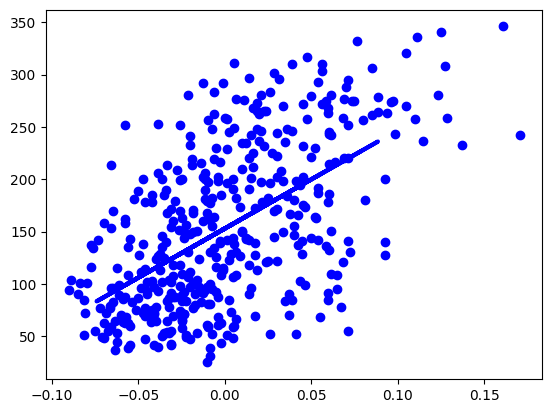

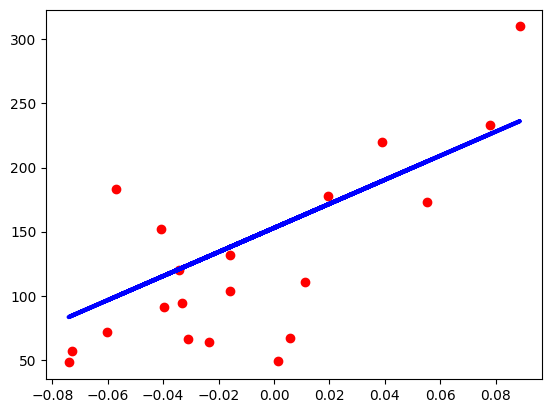

In [12]:
# 显示结果 

# 学到的系数
print('Coefficients: \n', regr.coef_)

# 均方误差（Mean Squared Error，MSE）
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
# 决定系数（Coefficient of Determination）R^2：一种方差评分，1 表示完美预测
print('Coefficient of determination R^2 (a variance score): %.2f' % r2_score(y_test, y_pred))

# 绘制训练数据及拟合直线
plt.figure(1)
plt.scatter(X_train, y_train, color='blue')
plt.plot(X_test, y_pred, color='blue', linewidth=3)

# 绘制测试数据及预测结果
plt.figure(2)
plt.scatter(X_test, y_test, color='red')
plt.plot(X_test, y_pred, color='blue', linewidth=3)

plt.show()

<a id="5.-Ridge-Regression"></a>

## 5. 岭回归（Ridge Regression）

[`Ridge`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge) 回归通过对系数的大小施加惩罚（Penalty），解决普通最小二乘法（Ordinary Least Squares，OLS）中的一些问题。岭回归的系数使带惩罚项的残差平方和最小：

$\min_{w} || X w - y||_2^2 + \alpha ||w||_2^2$.

复杂度参数 $\alpha \geq 0$（也记作 $\lambda$，称为*惩罚权重（Penalty Weight）*）控制*收缩（Shrinkage）*的程度：$\alpha$ 越大，收缩越强，系数的数值就越小，因而对*共线性（Collinearity）*，即变量之间的高度依赖，也更加稳健。

上面的目标函数是凸函数（Convex Function），因此比较“容易”使用已有的迭代优化方法求解。岭回归的计算复杂度与普通最小二乘法同阶，即 $O(n\,d^2)$。


<!-- classroom:ridge_penalty -->

### 课堂补充｜为什么不让模型自由地把系数调大？

老师从目标函数里的两项解释：第一项要求预测贴近数据，第二项要求权重向量不要太大。正则化并不只是追求训练误差最小，还要求模型为使用更大的权重付出代价。

当 alpha 为零时，惩罚项消失，回到普通最小二乘。逐渐增大 alpha，就是逐渐提高“保持系数较小”的重要性。老师把这看作对模型灵活性的约束：已有参数允许模型作很多调整，但不能仅为了贴合眼前样本，就不加限制地使用这些调整能力。

这里的“复杂度”是通过权重范数来控制的；它与直接减少参数个数不是一回事。课堂后面再用 Lasso 展示如何使部分系数恰好为零。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 112—130 行。*

<!-- /classroom:ridge_penalty -->



**简单示例**


In [13]:
from sklearn import linear_model
from sklearn.linear_model import Ridge

# 指定惩罚参数 alpha，设置模型
reg = linear_model.Ridge(alpha=.5)

# 对示例数据进行拟合
reg.fit([[0, 0], [0, 0], [1, 1]], [0, .1, 1]) 

# 显示模型的全部参数
reg

# 显示学到的系数和截距
print(reg.coef_)
print(reg.intercept_)


[0.34545455 0.34545455]
0.13636363636363638


[**绘制岭回归系数随正则化强度变化的曲线**](https://scikit-learn.org/stable/auto_examples/linear_model/plot_ridge_path.html#sphx-glr-download-auto-examples-linear-model-plot-ridge-path-py)

本例展示了以下内容：

* 变量的*共线性*（简单来说就是*高度依赖*）对岭回归估计器（Estimator）系数的影响。每种颜色代表系数向量中的一个不同系数，图中展示了它随正则化（Regularization）参数的变化。请记住：$\alpha$ 越大，正则化越强。

* 对高度病态的矩阵（Ill-conditioned Matrices）应用岭回归的作用。对于这样的矩阵，目标变量的微小变化就可能使计算出的权重产生很大的方差（Variance）。此时，设置一定强度的正则化（$\alpha$），可以通过增加模型的偏差（Bias）来降低这种方差，例如降低噪声引起的输出变化。

* 当 $\alpha$ 非常大时（图的右侧），正则化项在平方损失（Squared Loss）中占主导，系数向零收缩：解稳定，但偏差较大。当 $\alpha$ 趋于零时（图的左侧），解趋近于普通最小二乘解；由于矩阵是病态的，系数会变得很大，并随 $\alpha$ 剧烈变化：偏差低，但方差高。在实践中，需要调整 $\alpha$，使这两种情形达到平衡，例如使用交叉验证（Cross-Validation，CV），见下文的 `RidgeCV`。


<!-- classroom:ridge_path -->

### 课堂补充｜系数曲线不是把同一个解等比例缩小

读这张图时，先把一个固定的 alpha 看作一次完整拟合：选定 alpha，用相同数据求出一组权重，再把各个权重的值画出来。改变 alpha 后，需要重新优化，因此图上展示的是一系列不同的最优解。

老师特别指出：曲线不一定一起按相同比例下降。某个系数原本很小，在正则化增强的一段范围内反而可能变大，因为其他系数受到了更强限制，模型重新分配了各特征的作用。老师将此解释为可能由某个特征概括或替代其他特征的一部分信息。

**整理说明：** “概括其他特征”是课堂上的直观解释，不能仅凭曲线就判定真实因果作用。也不要把“整体收缩”读成“每个系数的绝对值都随 alpha 单调下降”。

正则化很弱时，病态问题中的权重可能对数据变化非常敏感；过强时，模型又可能失去描述问题所需的变化。老师用这个例子引出后面的偏差与方差权衡。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 130—164 行。*

<!-- /classroom:ridge_path -->



In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

# X 是 10×10 的希尔伯特矩阵（Hilbert Matrix）：X_ij = 1 / (i+j-1)
X = 1. / (np.arange(1, 11) + np.arange(0, 10)[:, np.newaxis])
y = np.ones(10)

# 显示数据矩阵
print(X)

[[1.         0.5        0.33333333 0.25       0.2        0.16666667
  0.14285714 0.125      0.11111111 0.1       ]
 [0.5        0.33333333 0.25       0.2        0.16666667 0.14285714
  0.125      0.11111111 0.1        0.09090909]
 [0.33333333 0.25       0.2        0.16666667 0.14285714 0.125
  0.11111111 0.1        0.09090909 0.08333333]
 [0.25       0.2        0.16666667 0.14285714 0.125      0.11111111
  0.1        0.09090909 0.08333333 0.07692308]
 [0.2        0.16666667 0.14285714 0.125      0.11111111 0.1
  0.09090909 0.08333333 0.07692308 0.07142857]
 [0.16666667 0.14285714 0.125      0.11111111 0.1        0.09090909
  0.08333333 0.07692308 0.07142857 0.06666667]
 [0.14285714 0.125      0.11111111 0.1        0.09090909 0.08333333
  0.07692308 0.07142857 0.06666667 0.0625    ]
 [0.125      0.11111111 0.1        0.09090909 0.08333333 0.07692308
  0.07142857 0.06666667 0.0625     0.05882353]
 [0.11111111 0.1        0.09090909 0.08333333 0.07692308 0.07142857
  0.06666667 0.0625     

In [15]:
# 计算正则化路径（Regularization Path）
n_alphas = 200
alphas = np.logspace(-10, -2, n_alphas)

coefs = []
for a in alphas:
    ridge = linear_model.Ridge(alpha=a, fit_intercept=False)
    ridge.fit(X, y)
    coefs.append(ridge.coef_)

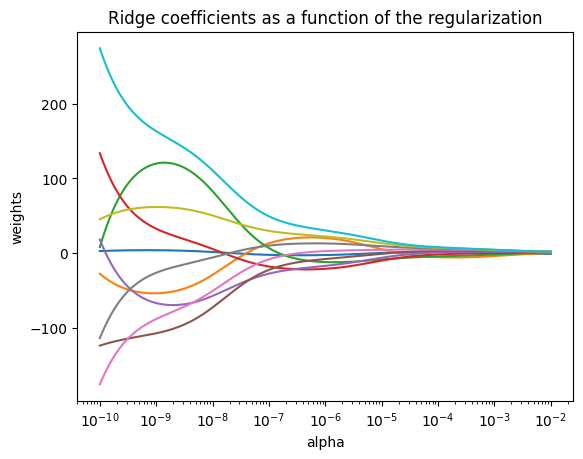

In [16]:
# 显示结果
ax = plt.gca()

ax.plot(alphas, coefs)
ax.set_xscale('log')
#ax.set_xlim(ax.get_xlim()[::-1])  # 如有需要，可反转 x 轴方向

plt.xlabel('alpha')
plt.ylabel('weights')
plt.title('Ridge coefficients as a function of the regularization')
plt.axis('tight')
plt.show()

**设置正则化参数：广义交叉验证（Generalized Cross-Validation，GCV）**

`RidgeCV` 实现了内置 $\alpha$ 参数交叉验证的岭回归。该对象的工作方式与 GridSearchCV 类似，区别在于它默认使用广义交叉验证，也就是一种高效的*留一交叉验证（Leave-one-out Cross-validation）*形式：每次仅留下一个数据对象作为测试集，其余全部作为训练集；重复这一过程，使每个数据对象都恰好作为测试集一次。


In [17]:
# 示例
import numpy as np
from sklearn import linear_model

reg = linear_model.RidgeCV(np.logspace(-6, 6, 13))
reg.fit([[0, 0], [0, 0], [1, 1]], [0, .1, 1])
   
print(reg.coef_)
print(reg.intercept_)
print('Best alpha: ', reg.alpha_)

[0.47146402 0.47146402]
0.0523573200992381
Best alpha:  0.01


<a id="6.-Lasso"></a>

## 6. Lasso

`Lasso` 是一种估计*稀疏（Sparse）*系数的线性模型。它倾向于选择非零系数更少的解，从而有效减少解所依赖的特征数量，因此在某些场景下很有用。也正因为如此，Lasso 及其变体是压缩感知（Compressed Sensing）领域的重要基础。在一定条件下，它能够精确恢复非零系数的集合。

这个线性模型对应的目标函数可写为：

$\min_{w} { \frac{1}{2n} ||X w - y||_2 ^ 2 + \alpha ||w||_1}$.

因此，Lasso 估计通过求解一个最小化问题得到：在最小二乘损失上加入正则化项 $\alpha ||w||_1$。其中，$\alpha$ 是常数，$||w||_1$ 是系数向量的 $\ell_1$ 范数（Norm），请注意它与岭回归使用的 $\ell_2$ 范数的区别。

上述优化问题没有通用的闭式解（Closed-form Solution），因此需要专门的求解方法。

`Lasso` 类的标准实现使用坐标下降（Coordinate Descent）优化算法拟合系数。当然，也有其他可选方法，例如交替优化（Alternating Optimization），而非简单的梯度下降（Gradient Descent）。

注意：Lasso 返回的是稀疏解，也就是说，许多特征对应的权重恰好为零。因此，它可以直接用作特征选择（Feature Selection）方法。


<!-- classroom:lasso_sparse -->

### 课堂补充｜为什么“同样好，但只用三个特征”值得关注？

Lasso 把惩罚从 L2 改为 L1。老师强调，这个看似很小的变化会改变优化问题的性质，也会改变解的形状：我们有机会得到一些系数严格为零的模型，而不只是得到一组普遍变小的系数。

课堂用疾病预测作例子：如果每位患者收集了五六十项指标，一个模型几乎用上所有指标，另一个模型只用三项，却得到相近的预测表现，后者就提出了更集中的研究问题：哪些信息真正有助于当前预测，哪些信息可能是重复的？

老师偏好这种在性能相近时更简洁的表示，因为它更容易帮助人理解模型所依赖的信息。

**整理说明：** 这是关于预测表示与解释性的例子。被选中的特征不自动等于疾病的病因，系数为零也不表示该因素在所有问题中都没有作用；结论受任务、数据和其他特征影响。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 166—174 行；[transcript_part2.md](./transcript_part2.md)，第 199—217 行。*

<!-- /classroom:lasso_sparse -->



**简单示例**


In [18]:
from sklearn import linear_model

reg = linear_model.Lasso(alpha=0.1)
reg.fit([[0, 0], [1, 1]], [0, 1])  

reg.predict([[1, 1]])

array([0.8])

**使用交叉验证进行 Lasso 模型选择（Model Selection）**

使用*赤池信息准则（Akaike Information Criterion，AIC）*、*贝叶斯信息准则（Bayes Information Criterion，BIC）*和交叉验证，为 Lasso 估计器选择最优的正则化参数 alpha。

$\text{AIC} = 2k - 2\ln(\hat{L})$

$\text{BIC} = k\cdot \ln(n) - 2\ln(\hat{L})$

上式中，$k$ 是模型参数的数量，$\hat{L}$ 是具有 $k$ 个参数的模型所能达到的最大似然，$n$ 是数据点数量。这里，仅 BIC 的惩罚项显式使用样本数量，因此其惩罚会随数据规模增大。对于含高斯噪声（Gaussian Noise）的回归，$-2\ln\hat{L}$ 在忽略一个常数后可化为 $n\ln(\text{RSS}/n)$，其中 RSS 表示残差平方和。因此，可以根据拟合模型的误差计算这些准则，例如 $\text{AIC} = n\ln(\text{RSS}/n) + 2k$。

LassoLarsIC 得到的结果基于 AIC/BIC 准则。

**基于信息准则的模型选择：** 这种方法速度很快，但依赖于对自由度（Degrees of Freedom）的恰当估计。这些准则是在大样本条件下推导出来的，属于渐近结果（Asymptotic Results），并且假设模型是正确的，也就是数据确实由该模型生成。当问题条件不佳时，例如特征数多于样本数，这些准则也往往会失效。

**交叉验证：** 这里采用 20 折交叉验证（20-fold Cross-validation），并使用两种算法计算 Lasso 路径：*坐标下降*（`LassoCV` 类）和*最小角回归（Least Angle Regression）*（`Lars`，由 `LassoLarsCV` 类实现）。两种算法得到的结果大致相同，但执行速度和数值误差的来源有所不同。

`Lars` 只在解逐步改善的路径上的每个拐点处计算路径解，这里的拐点指梯度增大或减小所体现的突变位置。因此，当拐点很少时，它非常高效；特征或样本较少时通常就是这种情况。此外，它无需设置额外的元参数，就能计算完整路径。

相比之下，坐标下降在预先指定的网格上计算路径点，这里使用默认网格。因此，当网格点的数量少于路径中的拐点数量时，它更高效。如果特征数量非常大，且有足够的样本支持选入较多特征，这种策略就可能很有吸引力。在数值误差方面，变量高度相关时，Lars 会累积更多误差，而坐标下降算法只在网格上对路径进行采样。

请注意，各折得到的最优 alpha 值会变化。这说明，当某个方法的参数通过交叉验证选择，而我们又希望评估该方法的性能时，为什么需要嵌套交叉验证（Nested Cross-Validation）：所选参数对于未见过的数据未必最优。


<!-- classroom:likelihood_bridge -->

### 课堂补充｜直线模型里为什么会出现似然？

有同学在信息准则这里需要补上一个连接：一条直线首先只给预测值，观测与预测的差是残差，它本身还没有描述这种差出现的可能程度。

老师让大家回到收入散点图：给定一个横坐标，点会在拟合直线的上下散开。如果进一步假设残差服从高斯分布（Gaussian Distribution），就可以把直线看作条件分布的中心，用噪声尺度描述上下散布的程度。这是在原来的预测关系之外，增加了一个概率假设。

有了这个假设，才可以讨论观测数据在模型下的似然，并把残差平方和与信息准则联系起来。同样大小的残差，在非常集中的分布和非常分散的分布下，可能代表不同程度的异常。

**整理说明：** 转录把连续观测的“概率”、概率密度（Probability Density）与似然口头混用了。这里说的是通过分布模型衡量观测的相对合理程度；不把“某个连续取值有 60% 概率”或“远处概率必定为零”作为精确结论。

随后，老师用奥卡姆剃刀解释为什么 AIC/BIC 还要考虑参数数量：拟合程度相近时，更复杂的模型需要额外理由。增加参数可以让模型更容易贴合数据，却不自动使它成为更好的选择。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 244—284 行。*

<!-- /classroom:likelihood_bridge -->



In [19]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV, LassoLarsCV, LassoLarsIC
from sklearn import datasets

# 避免调用 np.log10 时计算 log(0)
EPSILON = 1e-4

diabetes = datasets.load_diabetes()
X = diabetes.data
y = diabetes.target

rng = np.random.RandomState(42)
X = np.c_[X, rng.randn(X.shape[0], 14)]  # 添加一些无用特征

# 按照 Lars 的方式对数据归一化，以便比较
X /= np.sqrt(np.sum(X ** 2, axis=0))

Text(0.5, 1.0, 'Information-criterion for model selection (training time 0.093s)')

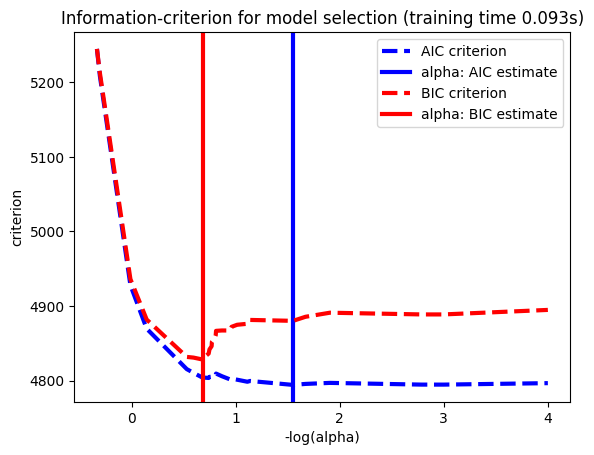

In [20]:
# LassoLarsIC：结合 BIC/AIC 准则的最小角回归
model_bic = LassoLarsIC(criterion='bic')
t1 = time.time()
model_bic.fit(X, y)
t_bic = time.time() - t1
alpha_bic_ = model_bic.alpha_

model_aic = LassoLarsIC(criterion='aic')
model_aic.fit(X, y)
alpha_aic_ = model_aic.alpha_


def plot_ic_criterion(model, name, color):
    alpha_ = model.alpha_ + EPSILON
    alphas_ = model.alphas_ + EPSILON
    criterion_ = model.criterion_
    plt.plot(-np.log10(alphas_), criterion_, '--', color=color, linewidth=3, label='%s criterion' % name)
    plt.axvline(-np.log10(alpha_), color=color, linewidth=3, label='alpha: %s estimate' % name)
    plt.xlabel('-log(alpha)')
    plt.ylabel('criterion')

plt.figure()
plot_ic_criterion(model_aic, 'AIC', 'b')
plot_ic_criterion(model_bic, 'BIC', 'r')
plt.legend()
plt.title('Information-criterion for model selection (training time %.3fs)'
          % t_bic)

Computing regularization path using the coordinate descent lasso...


(2300.0, 3800.0)

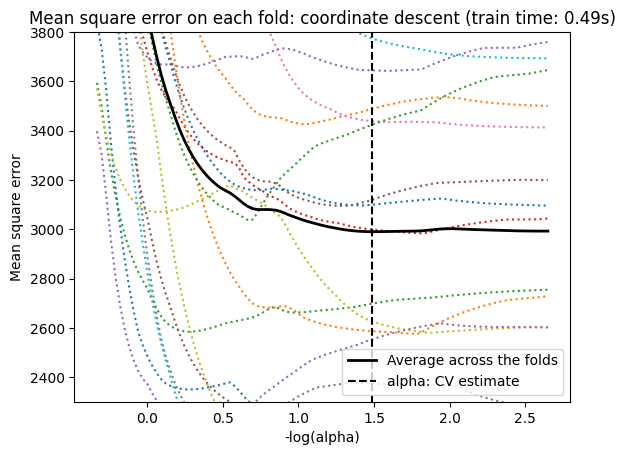

In [21]:
# LassoCV：坐标下降

# 计算正则化路径（Regularization Path）
print("Computing regularization path using the coordinate descent lasso...")
t1 = time.time()
model = LassoCV(cv=20).fit(X, y)
t_lasso_cv = time.time() - t1

# 显示结果
m_log_alphas = -np.log10(model.alphas_ + EPSILON)

plt.figure()
ymin, ymax = 2300, 3800
plt.plot(m_log_alphas, model.mse_path_, ':')
plt.plot(m_log_alphas, model.mse_path_.mean(axis=-1), 'k', label='Average across the folds', linewidth=2)
plt.axvline(-np.log10(model.alpha_ + EPSILON), linestyle='--', color='k', label='alpha: CV estimate')

plt.legend()

plt.xlabel('-log(alpha)')
plt.ylabel('Mean square error')
plt.title('Mean square error on each fold: coordinate descent (train time: %.2fs)' % t_lasso_cv)
plt.axis('tight')
plt.ylim(ymin, ymax)

<a id="7.-Elastic-net"></a>

## 7. 弹性网（Elastic Net）

弹性网在同一个优化问题中同时使用 Lasso 和岭回归的惩罚项，这时使用两个权重参数 $\alpha_1$ 和 $\alpha_2$：

$\min_{w} { \frac{1}{2n} ||X w - y||_2 ^ 2 + \alpha_1 ||w||_1 + \alpha_2 ||w||_2^2}$.

与 Lasso 一样，这个问题没有通用的闭式解。

可以在[这里](https://towardsdatascience.com/from-linear-regression-to-ridge-regression-the-lasso-and-the-elastic-net-4eaecaf5f7e6)查看比较这三种正则化方法的示例。


<!-- classroom:elastic_joint -->

### 课堂补充｜为什么先做 Lasso、再做岭回归，不等于弹性网？

弹性网把两种惩罚放在同一个目标函数里，让优化过程同时考虑稀疏性与收缩。老师同时提醒：多加一种惩罚，也多了需要选择的控制量。

**参数与超参数的区别：** 权重 w 是模型从数据中拟合的参数；alpha 控制拟合时惩罚的重要程度，是超参数。超参数不是天然已知的常数，也需要通过模型选择过程来确定。

**课堂问答：能否先用 Lasso 筛掉一些特征，再用岭回归？** 老师认为这可以作为一种工程方案尝试，但不能直接当作同一个优化问题。分阶段处理时，第一步已在没有第二种惩罚参与的情况下作了选择；共同优化时，两种惩罚会互相影响，合适的系数和超参数都可能不同。因此，先后执行的效果要单独评估，不能预先保证等价或更优。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 226—243 行。*

<!-- /classroom:elastic_joint -->



<a id="8.-Regularization-norms-in-optimization"></a>

## 8. 优化中的正则化范数

首先，看看范数 $||x||_p$ 的形状，以及它们对输入向量 $x \in \mathbb{R}^2$ 施加的约束。在下图中，从原点出发、终点位于红线上任意位置的所有向量，都具有相同的范数：

![不同范数的等值线](l1vsl2norms_2.png)

Lasso、岭回归及其他形式的回归方法，会受到其惩罚项所用范数性质的影响。注意，现代方法可以同时使用 $\ell_1$ 和 $\ell_2$：

**$\ell_0$：** 稀疏性（Sparsity）的理想目标，但在计算上难以处理。

**$\ell_1$：** 一种有望施加稀疏性的松弛（Relaxation）；在技术上较难处理；对离群点（Outliers）稳健，但解不稳定。

**$\ell_2$：** 得到非稀疏的解，仅对系数进行*收缩*；可以使用高效的优化技术，较易求解；对离群点敏感，但解稳定。

**$\ell_1$ 与 $\ell_2$：** 弹性网采用的组合，结合了两种惩罚项的几何性质。

> 译注：原文对离群点稳健性的表述较笼统。这里比较的是系数惩罚项；使用 Lasso 的系数惩罚，并不意味着采用平方损失的回归模型就能抵抗响应值中的离群点。还需区分对系数施加惩罚与对残差采用不同损失函数。

下图展示了这些正则化方法的几何性质。$\theta_\text{opt}$ 是我们试图通过优化方案逼近的某个最优解；对于回归示例，它就是最优系数向量 $w_\text{opt}$。绿色点表示相应范数约束区域中最接近 $\theta_\text{opt}$ 的点。

![Lasso、岭回归与弹性网的几何示意图](l1-l2-elastic.png)

> 图片说明：当前课程文件中缺少原文引用的 `l1-l2-elastic.png`，此处保留原引用，待补齐图片后即可显示。

图片来源：Zou 等，*Regularization and variable selection via the elastic net*（通过弹性网进行正则化与变量选择），Journal of the Royal Statistical Society: Series B，2005 年。


<!-- classroom:norm_geometry -->

### 课堂补充｜图里的一个点，代表一个模型，不是一个样本

老师在这里反复澄清坐标轴的含义：前面的散点图画的是数据，而这张图画的是参数空间（Parameter Space）。如果模型由两个参数决定，那么每一组参数就是平面上的一个点；更换一组参数，相当于换成另一个模型。

彩色区域表示惩罚所对应的可行域（Feasible Region），也就是允许考虑的参数组合。几何图要帮助我们理解：当理想解在区域之外时，约束如何影响我们最终选中的参数。

- L2 区域的边界是圆滑的，落在边界上的解一般仍有多个非零坐标。
- L1 区域带有位于坐标轴上的角点；落在角点时，就有某个参数恰好为零。在一定范围内改变目标位置，最优点仍可能停留在同一个角点，这提供了理解稀疏性的直观方式。
- 弹性网同时保留部分尖角与弯曲边界，体现了两种惩罚共同作用的效果。

老师用“更接近理想参数”的图像帮助理解优化过程，并解释零系数意味着该特征没有参与当前模型的预测。

**整理说明：** 图中的“最近”应结合具体损失函数的等高线理解，不普遍等于普通欧氏距离；角点示例也不意味着 Lasso 在所有数据条件下都稳定或始终返回同一组特征。这里整理的是图所表达的机制。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 175—205 行；[transcript_part2.md](./transcript_part2.md)，第 220—229 行。*

<!-- /classroom:norm_geometry -->



<a id="9.-Robust-Linear-Regression"></a>

## 9. 稳健线性回归（Robust Linear Regression）

关于这一迭代方法的阅读资料：

* 用于稳健线性回归的[随机采样一致性（RANdom SAmple Consensus，RANSAC）](https://en.wikipedia.org/wiki/Random_sample_consensus)方法。
* [《RANSAC 算法概述》（Overview of the RANSAC Algorithm）](http://www.cse.yorku.ca/~kosta/CompVis_Notes/ransac.pdf)，K.G. Derpanis，2010 年。
* [《RANSAC 系列方法的性能评估》（Performance Evaluation of RANSAC Family）](http://www.bmva.org/bmvc/2009/Papers/Paper355/Paper355.pdf)，Sunglok Choi、Taemin Kim 和 Wonpil Yu，BMVC，2009 年。

RANSAC 利用完整数据集中内点（Inliers）的随机子集来拟合模型。它是一种非确定性算法（Non-deterministic Algorithm），只能以一定概率得到合理结果，这个概率取决于迭代次数。它通常用于线性和非线性回归问题，在计算机视觉（Computer Vision）领域尤其常见。

该算法将全部输入样本划分为内点与离群点两类。内点也可能受到噪声影响，而离群点可能来自错误的测量，或对数据所作的不成立的假设。最终，仅根据确定下来的内点估计模型。

**算法细节**

每次迭代执行以下步骤：

1. 从原始数据中随机选取 ``min_samples`` 个样本，并检查这组数据是否有效，见 ``is_data_valid``。
2. 在这个随机子集上拟合模型（``estimator.fit``），并检查估计出的模型是否有效，见 ``is_model_valid``。
3. 计算所有数据相对于估计模型的残差（``estimator.predict(X) - y``），据此将它们划分为内点或离群点：绝对残差小于 ``residual_threshold`` 的样本被视为内点。
4. 如果内点数量达到当前最大值，就将拟合模型保存为最佳模型。如果当前模型与已有最佳模型的内点数相同，则只有评分更高时，才将其视为最佳模型。

重复上述步骤，直到达到最大尝试次数（``max_trials``），或满足某个特定停止条件，见 ``stop_n_inliers`` 和 ``stop_score``。最后，使用此前确定的最佳模型的全部内点样本，即一致集（Consensus Set），通过简单线性回归估计最终模型。

``is_data_valid`` 和 ``is_model_valid`` 函数可用于识别并排除随机子样本中的退化组合（Degenerate Combinations）。如果无需拟合模型就能识别退化情况，应使用 ``is_data_valid``，因为它在模型拟合之前调用，计算效率更高。

下图中，假设我们抽取了红圈标出的两个点，并据此建立了线性模型。

<img src="ransac.png" alt="根据两个随机样本拟合直线并识别内点" style="width: 600px;"/>

**使用 scikit-learn 应用 RANSAC**

下面使用 scikit-learn 库中现成的方法，在一个示例数据集上展示 [RANSAC 的应用](https://scikit-learn.org/stable/auto_examples/linear_model/plot_ransac.html)。请记住，这里实现的功能，正是作业 1 的练习 1 要求你从零实现该算法时应达到的目标。


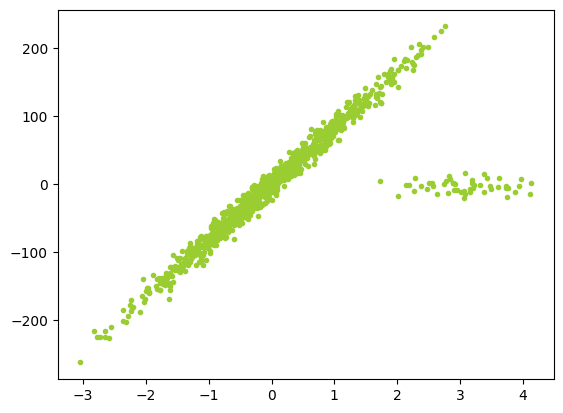

In [22]:
import numpy as np
from matplotlib import pyplot as plt
from sklearn import linear_model, datasets

N_samples = 1000
N_outliers = 50

X, y, coef = datasets.make_regression(n_samples=N_samples, n_features=1, n_informative=1, noise=10, coef=True, random_state=0)

# 添加离群点数据
np.random.seed(0)
X[:N_outliers] = 3 + 0.5 * np.random.normal(size=(N_outliers, 1))
y[:N_outliers] = -3 + 10 * np.random.normal(size=N_outliers)

plt.scatter(X, y, color='yellowgreen', marker='.', label='Data')

**完整示例**


Estimated coefficients (true, linear regression, RANSAC):
82.1903908407869 [54.17236387] [82.08533159]


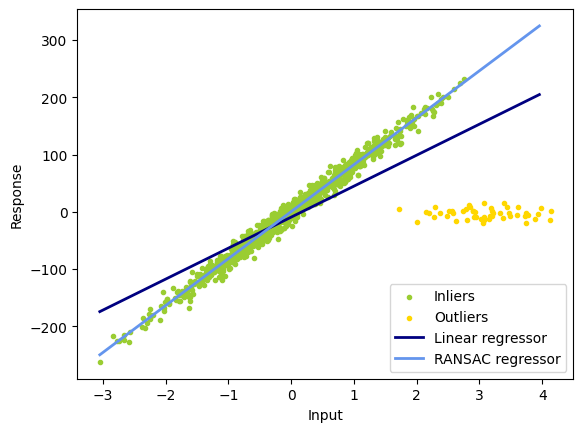

In [23]:
import numpy as np
from matplotlib import pyplot as plt

from sklearn import linear_model, datasets


n_samples = 1000
n_outliers = 50


X, y, coef = datasets.make_regression(n_samples=n_samples, n_features=1,
                                      n_informative=1, noise=10,
                                      coef=True, random_state=0)

# 添加离群点数据
np.random.seed(0)
X[:n_outliers] = 3 + 0.5 * np.random.normal(size=(n_outliers, 1))
y[:n_outliers] = -3 + 10 * np.random.normal(size=n_outliers)

# 使用全部数据拟合直线
lr = linear_model.LinearRegression()
lr.fit(X, y)

# 使用 RANSAC 算法稳健地拟合线性模型
ransac = linear_model.RANSACRegressor()
ransac.fit(X, y)
inlier_mask = ransac.inlier_mask_
outlier_mask = np.logical_not(inlier_mask)

# 使用估计出的模型进行预测
line_X = np.arange(X.min(), X.max())[:, np.newaxis]
line_y = lr.predict(line_X)
line_y_ransac = ransac.predict(line_X)

# 比较估计出的系数
print("Estimated coefficients (true, linear regression, RANSAC):")
print(coef, lr.coef_, ransac.estimator_.coef_)

lw = 2
plt.scatter(X[inlier_mask], y[inlier_mask], color='yellowgreen', marker='.', label='Inliers')
plt.scatter(X[outlier_mask], y[outlier_mask], color='gold', marker='.', label='Outliers')
plt.plot(line_X, line_y, color='navy', linewidth=lw, label='Linear regressor')
plt.plot(line_X, line_y_ransac, color='cornflowerblue', linewidth=lw, label='RANSAC regressor')
plt.legend(loc='lower right')
plt.xlabel("Input")
plt.ylabel("Response")
plt.show()

<a id="10.-Fitting-Ordinary-Linear-Regression-and-Logistic-Regression"></a>

## 10. 普通线性回归与逻辑回归（Logistic Regression）的拟合

下面通过一个较详细的示例，比较标准线性回归（Standard Linear Regression，SLR）与逻辑回归（LR）这两种方法。

**线性回归**

首先使用普通最小二乘法进行标准线性回归。

所处理的问题包含 $n$ 个数据样本，即数据点；目标变量 $y$ 是一个连续变量（Continuous Variable），表示给定 $x$ 时某个事件发生的概率。


   x_i   y_i
[[9.4  0.71]
 [1.6  0.43]
 [3.2  0.67]
 [4.2  0.92]
 [1.6  0.37]
 [3.2  0.74]
 [2.5  0.08]
 [0.4  0.45]
 [6.5  0.8 ]
 [4.3  0.94]]


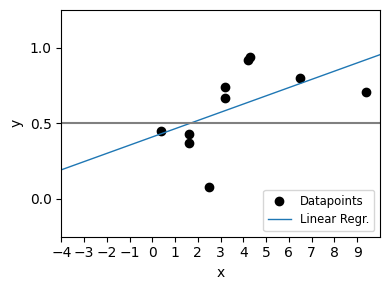

In [24]:
# 简单线性回归
import numpy as np
import matplotlib.pyplot as plt

from sklearn import linear_model
from scipy.special import expit

# 一条带有高斯噪声的直线
n = 10     # 样本数量
np.random.seed(7)
X = np.random.normal(size=n)
y = (X > 0).astype(float)
y = (y-0.5) * np.random.uniform(0.1, 0.9, (n,)) + 0.5   # 将其看作连续变量，例如概率
y = np.ceil(y*100)/100            # 简单调整数值精度，便于打印显示

X[X > 0] *= 4
X += 2.5 + .3 * np.random.normal(size=n)

X = np.ceil(X*10)/10            # 简单调整数值精度，便于打印显示
X = X[:, np.newaxis]

# 显示 (x_i,y_i) 数据对
print('   x_i   y_i')
print(np.concatenate((X,y.reshape(n,1)), axis=1))

plt.figure(1, figsize=(4, 3))
plt.scatter(X, y, color='black',)

# 普通线性回归
ols = linear_model.LinearRegression()
ols.fit(X, y)

X_test = np.linspace(-5, 10, 300)
plt.plot(X_test, ols.coef_ * X_test + ols.intercept_, linewidth=1)
plt.axhline(.5, color='.5')

plt.ylabel('y')
plt.xlabel('x')
plt.xticks(range(-5, 10))
plt.yticks([0, 0.5, 1])
plt.ylim(-.25, 1.25)
plt.xlim(-4, 10)
plt.legend(('Datapoints','Linear Regr.'),loc="lower right", fontsize='small')
plt.tight_layout()
plt.show()

### 普通最小二乘法拟合

设 $P$ 是一个包含 $n$ 个二维点的数据集，$p_i = (x_i,y_i)$，其中 $x_i$ 是输入（自变量），$y_i$ 是输出（因变量）。假设我们希望找到最贴合 $P$ 中各点的直线。下面讨论普通最小二乘法如何通过估计参数来拟合线性模型。

回顾带噪声项 $\epsilon_i$ 的线性模型，其中噪声是均值为零的高斯噪声：

$$ y_i  = w_0 + w_1x_i + \epsilon_i, \ \ i=1,...,n $$

目标是相对于模型参数 $w_0$、$w_1$，最小化以下损失函数（Loss Function）：

$$ \phi(w_0, w_1) = \sum_{i=1}^n (y_i - w_0 - w_1 x_i)^2 = \sum_{i=1}^n \epsilon_i^2$$

这个优化问题可以写为：

$$ \hat{w}_0, \hat{w}_1 = \arg\!\min_{w_0, w_1} \phi(w_0, w_1) = \sum_{i=1}^n (y_i - w_0 - w_1 x_i)^2$$

为了寻找最优解，需要分别对两个参数求偏导数（Partial Derivative）并令其为零，以考察目标函数的极值点。这里使用记号 $\nabla_{\theta}(\cdot) = \frac{\partial \mathcal{(\cdot)}}{\partial \theta}$：

$$\text{1)} \quad \nabla_{w_0}\mathcal{\phi} = -2 \sum_{i=1}^n (y_i - w_0 - w_1 x_i) = 0$$

$$\text{2)} \quad  \nabla_{w_1}\mathcal{\phi}  = -2 \sum_{i=1}^n (y_i - w_0 - w_1 x_i)x_i = 0$$

注意，这里的极值点是最小值点。原文给出的理由是：目标函数没有最大值，因为随 $w$ 的变化，损失可以任意大。由式（1）得到：

$$ -2 \sum_{i=1}^n (y_i - w_0 - w_1 x_i) = 0 $$

$$ \sum_{i=1}^n y_i - n w_0 - w_1 \sum_{i=1}^n x_i = 0 $$

$$ w_0 =  \frac{1}{n}\sum_{i=1}^n y_i - w_1 \frac{1}{n}\sum_{i=1}^n x_i$$

$$ \Rightarrow \hat{w}_0 = \bar{y} - \hat{w}_1 \bar{x}$$

请记住，$\sum_{i=1}^n y_i = n \bar{y}$，并且 $\sum_{i=1}^n x_i = n \bar{x}$。

接着，由式（2）得到：

$$ -2 \sum_{i=1}^n (y_i - w_0 - w_1 x_i)x_i = 0$$

$$ \sum_{i=1}^n (y_i - (\bar{y} - w_1 \bar{x}) - w_1 x_i)x_i = 0$$

$$ \sum_{i=1}^n x_i y_i - \bar{y} \sum_{i=1}^n x_i + w_1 \sum_{i=1}^n x_i + w_1 \bar{x}\sum_{i=1}^n x_i^2 = 0$$

$$ w_1 = \frac{\sum_{i=1}^n x_i y_i - n \bar{x} \bar{y}}{\sum_{i=1}^n x_i^2 - n \bar{x}}$$

$$ \Rightarrow \hat{w}_1 = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^n (x_i - \bar{x})^2}$$

> 译注：本段原式存在笔误：代入截距后，展开式的后两项有误；分式分母中的均值项缺少平方。最后一行的中心化斜率公式是正确的。另需注意，判定驻点为最小值的依据是该目标函数为凸二次函数，仅凭“没有最大值”并不足以作出这一判断。以上公式按原文保留。

用矩阵形式表示时，给定由 $x_i$ 组成的矩阵 $X$，可写为：

$$
\hat{w} =(X^\top X)^{-1}(X^\top Y)
$$

利用 $(X^\top X)^{−1}(X^\top X)=I$（逆矩阵必须存在！）以及 $Iw=w$，其中 $I$ 是单位矩阵（Identity Matrix），可以得到：

$$
\hat{w} =(X^\top X)^{-1}(X^\top (Xw + E))
$$

$$
\hat{w} = w + (X^\top X)^{-1}(X^\top E)
$$

这说明，由于误差 $E$ 的存在，估计值 $\hat{w}$ 与真实值 $w$ 会有差异。请记住，真实的 $w$ 是一个未知常数，而估计值 $\hat{w}$ 因误差 $E$ 的存在而成为随机变量（Random Variable）。因此，估计值 $\hat{w}$ 随着用于估计它的样本数据集 $X$ 而变化，是正常的。


### 逻辑回归

现在考虑另一个问题：输入数据 $X$ 相同，但给定的目标变量 $y$ 是二元变量（Binary Variable）。它可以表示某个事件的结果，即每次给定数据 $x_i$ 时，事件是否发生：发生时 $y_i=1$，否则 $y_i=0$。注意，在这个具体示例中，相当于对普通线性回归情形中的 $y_i$ 进行了取整。

模型针对类别变量（Categorical Variable）进行回归，这也解释了为什么逻辑回归实际上是一种二分类（Binary Classification）方法。

**示例**

<img src="Exam_pass_logistic_curve.svg.png" alt="考试通过概率的逻辑回归曲线" style="width: 500px;"/>


  x_i y_i
[[9.1 1. ]
 [2.  0. ]
 [2.8 1. ]
 [4.1 1. ]
 [1.7 0. ]
 [2.1 1. ]
 [2.7 0. ]
 [0.8 0. ]
 [6.7 1. ]
 [4.5 1. ]]


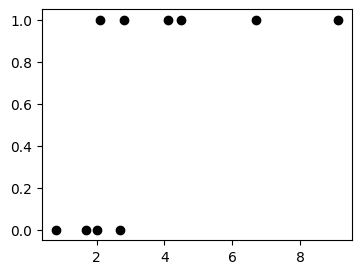

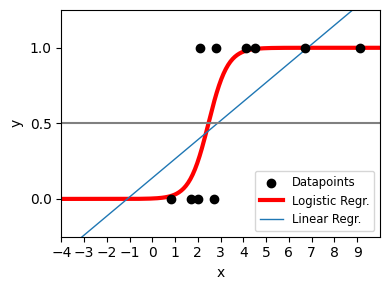

In [25]:
# 逻辑回归
#%% 相同的数据：一条带有高斯噪声的直线
n = 10             # 样本数量
np.random.seed(7)
X = np.random.normal(size=n)
y = (X > 0).astype(float)

X[X > 0] *= 4
X += 2.5 + .3 * np.random.normal(size=n)

X = np.ceil(X*10)/10            # 简单调整数值精度，便于打印显示
X = X[:, np.newaxis]

# 显示 (x_i,y_i) 数据对
print('  x_i y_i')
print(np.concatenate((X,y.reshape(n,1)), axis=1))

plt.figure(1, figsize=(4, 3))
plt.scatter(X, y, color='black',)

# 拟合分类器（Classifier）
clf = linear_model.LogisticRegression(C=1e5)
clf.fit(X, y)

# 绘制结果
plt.figure(2, figsize=(4, 3))
plt.clf()
plt.scatter(X.ravel(), y, color='black', zorder=20)
X_test = np.linspace(-5, 10, 300)

loss = expit(X_test * clf.coef_ + clf.intercept_).ravel()
plt.plot(X_test, loss, color='red', linewidth=3)

ols = linear_model.LinearRegression()
ols.fit(X, y)
plt.plot(X_test, ols.coef_ * X_test + ols.intercept_, linewidth=1)
plt.axhline(.5, color='.5')

plt.ylabel('y')
plt.xlabel('x')
plt.xticks(range(-5, 10))
plt.yticks([0, 0.5, 1])
plt.ylim(-.25, 1.25)
plt.xlim(-4, 10)
plt.legend(('Datapoints','Logistic Regr.', 'Linear Regr.'),
           loc="lower right", fontsize='small')
plt.tight_layout()
plt.show()



**逻辑回归拟合**

上图中的红色曲线是逻辑 Sigmoid 函数（Logistic Sigmoid Function），形状类似字母 S。本方法正是用这一函数来建立数据模型。

概率模型（Probabilistic Model）为：

$$p(x)=\frac{1}{1+e^{-(\beta_0+\beta_1 x)}}$$

基本上，原文将这个表达式描述为：在数据的对数尺度下考虑直线 $y = \beta_0+\beta_1 x$。在这个意义上，$\beta_0$ 是纵向截距，$\beta_1$ 是逆尺度参数。

> 译注：更准确地说，呈线性关系的是概率的对数几率（Log-odds），而不是原始数据的对数。

为简化记号，可以令 $\beta = \begin{pmatrix}-\beta_{0} \\ -\beta_{1} \end{pmatrix}$，并给数据增加一个固定为 $1$ 的辅助维度，即 $x := \begin{pmatrix} 1 \\ x\end{pmatrix}$。这样，模型可写为：

$$ p(x)= \sigma(\beta^\top x) = \frac{1}{1+e^{\beta^\top x}} $$

此时，拟合模型就是根据输入数据估计 $\beta_0$ 和 $\beta_1$。

我们使用*逻辑损失（Logistic Loss）*，它衡量数据让模型感到多么“意外”。令 $p_i = p(x_i)$，其值始终位于 $[0,1]$ 内，相应的对数非正。那么，每个 $(x_i, y_i)$ 对应的损失为：

$$\ell_i = \begin{cases}
-\ln p_i & \text{ if } y_i = 1, \\
-\ln (1 - p_i) & \text{ if } y_i = 0.
\end{cases}$$

可以把这个损失合并为一个表达式：

$$\ell_i = - y_i \ln p_i - (1-y_i) \ln (1-p_i)$$

根据 $y_i$ 的取值，其中只有一项起作用。

原文接着提出“直接最小化负的逻辑损失（$-\ell$）”，并称下面要“最大化损失的逆，也就是对数似然”。

> 译注：此句的符号与措辞有误。正确的对应关系是：**最小化逻辑损失，等价于最大化对数似然（Log-likelihood）**。这里是取负号，不是取倒数。另外，本节将参数向量定义为带负号的形式，后续推导却未始终沿用这一约定，阅读时需留意。


**最大似然估计（Maximum Likelihood Estimation，MLE）**

这种学习方法适用于为观测数据赋予概率的概率模型。首先定义这里的**似然**：在逻辑回归模型下，观测到给定输入数据的可能程度。似然的一般写法是 $L(\text{data observations} \ |\  \text{model})$，即“给定模型时观测数据的似然”。在这里，观测数据是 $(X,y)$，模型由参数 $\beta$ 确定，因此写作 $L(X,y \ | \ \beta)$：

$$L = \prod_{i:y_i=1} p_i \ \cdot\ \prod_{i:y_i=0} (1-p_i)$$

于是，**对数似然**为（同样，完整写法是 $\mathcal{L}(X,y \ | \ \beta_0, \beta_1)$）：

$$\mathcal{L} = \ln(L) = \ln \left(\prod_{i:y_i=1} p_i\right) \ \cdot\ \ln\left(\prod_{i:y_i=0} (1-p_i)\right)$$

$$ = \left(\sum_{i:y_i=1} \ln(p_i)\right) \ + \ \left(\sum_{i:y_i=0} \ln(1-p_i)\right)$$

$$ = \sum_{i=1}^n y_i \ln(p_i) + (1-y_i)\ln(1-p_i)$$

> 译注：上面第一行两个对数之间的乘号是原文笔误，应为加号；下一行使用的是正确的相加形式。

将 $p_i$ 替换为完整表达式，并进行计算，得到：

$$\mathcal{L} = \sum_{i=1}^n y_i \beta x_i + \log\left(\frac{1}{1+e^{\beta^\top x}}\right)$$

最大化该表达式，等价于最大化下面这个**最终的对数似然函数**：

$$\mathcal{L} = \sum_{i=1}^n y_i \beta x_i - \log(1+e^{\beta^\top x})$$

> 译注：原文这两式的求和范围、样本下标及参数符号约定并不严谨：每个样本对应的对数项也应包含在求和中，参数还需与上一节采用的符号定义保持一致。此处保留原式，未将它们作为已经校正的推导。


我们需要分别对每个参数求偏导，并寻找这些偏导数等于 $0$ 的条件：

$$\nabla_{\beta_0}\mathcal{L} = \sum_{i=1}^n (y_i-p_i) = 0 $$

$$\nabla_{\beta_1}\mathcal{L} = \sum_{i=1}^n (y_i-p_i)x_i = 0$$

这个方程组并不容易求解，因此需要采用数值方法（Numerical Methods），例如不动点迭代（Fixed-point Iteration）、二分法（Bisection Method）、牛顿—拉夫森法（Newton–Raphson Method）等。这里使用最后一种方法，它是一种迭代方法，在第 $t$ 次迭代中的更新规则为：

$$
\beta^{(t+1)} = \beta^{(t)} - \frac{\nabla_{\beta}\mathcal{L}(\beta^{(t)})}{\nabla^2_{\beta}\mathcal{L}(\beta^{(t)})}
$$

其中，$\nabla_{\beta}\mathcal{L}(\beta^{(t)})$ 和 $\nabla^2_{\beta}\mathcal{L}(\beta^{(t)})$ 分别是对数似然关于 $\beta$ 的一阶导数和二阶导数。


经过计算，得到：

$$\nabla_{\beta}\mathcal{L}(\beta^{(t)}) = \sum_{i=1}^n (y_i - p_i) x_i$$

$$\nabla^2_{\beta}\mathcal{L}(\beta^{(t)}) = \sum_{i=1}^n p_i (1 - p_i) x_i^\top x_i$$

这些结果的矩阵形式为：

$$\nabla_{\beta}\mathcal{L}(\beta^{(t)}) = X(Y-\hat{Y})$$

$$\nabla^2_{\beta}\mathcal{L}(\beta^{(t)}) = X^\top W X$$

其中，$W = P(1-P)$。

> 译注：原文此处的梯度（Gradient）与海森矩阵（Hessian Matrix）存在符号和维度问题。按第 3 章“每行一个样本”的设计矩阵约定，梯度中的数据矩阵应转置；通常的对数似然海森矩阵应带负号。权重矩阵应为对角矩阵，各对角元素为对应样本的预测概率乘以其补概率，而不是未定义清楚的向量乘积。


因此，**使用牛顿—拉夫森优化方法求解最大似然估计**，需要反复执行以下更新：

$$
\beta^{(t+1)} = \beta^{(t)} - \frac{\nabla_{\beta}\mathcal{L}(\beta^{(t)})}{\nabla^2_{\beta}\mathcal{L}(\beta^{(t)})} = \beta^{(t)} - \frac{X(Y-\hat{Y}^{(t)})}{X^\top W^{(t)} X} = \beta^{(t)} - X(Y-\hat{Y}^{(t)})({X^\top W^{(t)} X})^{-1} 
$$

显然，当数据维度大于一时，这种更新的开销较高，因为每次都需要对矩阵求逆。不过，原文认为，在本例只有一个特征的情况下，$X^\top W^{(t)} X$ 是一个标量，因此不会带来这一复杂性。

> 译注：这里延续了上一段的符号与矩阵维度问题。对参数向量应用牛顿法时，应使用海森矩阵求解线性方程组，不能直接把向量除以矩阵。即使只有一个输入特征，只要同时估计截距和斜率，就仍有两个参数，对应的海森矩阵也不是标量。原式保留供对照，不宜直接据此实现算法。


<a id="11.-Underfitting-vs-Overfitting:-Example-in-Polynomial-Regression"></a>

## 11. [欠拟合与过拟合：多项式回归示例](https://scikit-learn.org/stable/auto_examples/model_selection/plot_underfitting_overfitting.html#sphx-glr-auto-examples-model-selection-plot-underfitting-overfitting-py)

**奥卡姆剃刀（Occam's Razor）**是一条通常归于 14 世纪修士奥卡姆的威廉的原则：如果有两种相互竞争的观点可以解释同一现象，应优先选择较简单的那个。简单来说，对某个现象的解释所需的假设越少、复杂度越低，这种解释就越好。

模型复杂度有以下三种典型情形：

- **欠拟合（Underfitting）：** 模型不足以拟合训练样本。
- **拟合恰当（Good-fitting）：** 模型足以捕捉或描述数据。在下面的示例中，四次多项式几乎完美地逼近了真实函数，这属于多项式回归（Polynomial Regression）。
- **过拟合（Overfitting）：** 模型将问题过度复杂化，给出的解比数据背后的真实关系更复杂。下方第三幅、也就是最右侧的图展示了这种情况。


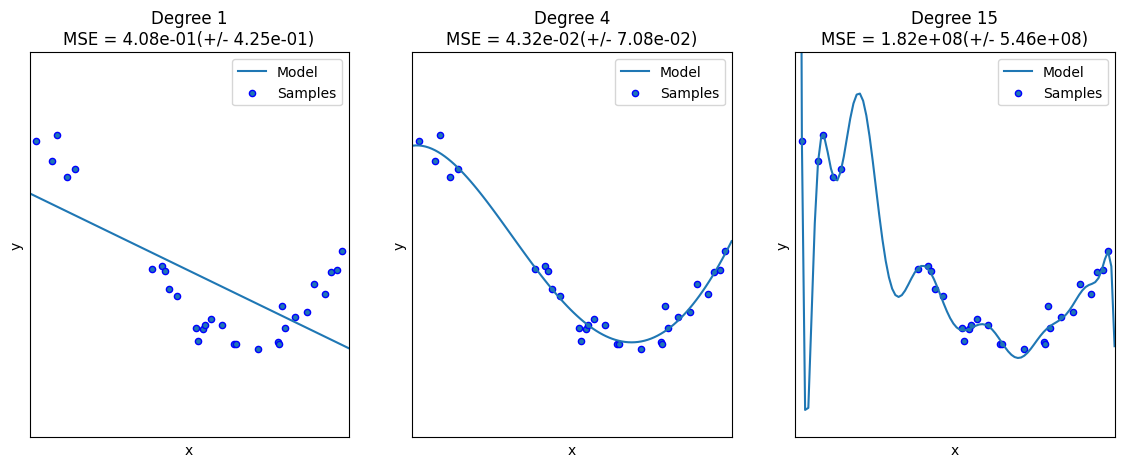

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score


def true_fun(X):
    return np.cos(1.5 * np.pi * X)

np.random.seed(0)

n_samples = 30
degrees = [1, 4, 15]

X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1

plt.figure(figsize=(14, 5))
for i in range(len(degrees)):
    ax = plt.subplot(1, len(degrees), i + 1)
    plt.setp(ax, xticks=(), yticks=())

    polynomial_features = PolynomialFeatures(degree=degrees[i],
                                             include_bias=False)
    linear_regression = LinearRegression()
    pipeline = Pipeline([("polynomial_features", polynomial_features),
                         ("linear_regression", linear_regression)])
    pipeline.fit(X[:, np.newaxis], y)

    # 使用交叉验证评估模型
    scores = cross_val_score(pipeline, X[:, np.newaxis], y, scoring="neg_mean_squared_error", cv=10)

    X_test = np.linspace(0, 1, 100)
    plt.plot(X_test, pipeline.predict(X_test[:, np.newaxis]), label="Model")
    plt.scatter(X, y, edgecolor='b', s=20, label="Samples")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc="best")
    plt.title("Degree {}\nMSE = {:.2e}(+/- {:.2e})".format(degrees[i], -scores.mean(), scores.std()))
plt.show()



<!-- classroom:polynomial_reading -->

### 课堂补充｜15 次多项式几乎穿过所有点，为什么反而有问题？

老师让大家依次看一次、四次、十五次模型。一次模型过于简单，无法跟随数据的弯曲趋势；四次模型能更好地描述这种变化；继续提高到十五次后，很多训练点上的残差确实更小了。

问题出在没有观测的位置：十五次模型可能突然大幅向上或向下摆动。训练目标只能检查现有样本，没有样本的位置就没有相应误差去约束这些摆动。于是，模型可以一边非常贴近训练点，一边在点与点之间给出不合理的预测。

**课堂问答：换一批数据会怎样？** 新样本一旦落在剧烈摆动的位置，小训练误差就不能保证预测仍然好。下面加入生成数据的真实函数，是为了把这种差别看得更清楚。在真实问题里我们通常不知道真实函数，因此还需要用未参与训练的数据来评估。

老师以此回到前面的原则：在效果相近的候选方案中，优先考虑更简单的解释；不能只因为训练残差还能降低，就不停增加复杂度。这里的 4 次是本例的观察，不是适用于所有数据的最佳阶数。

*转录来源：[transcript_part3.md](./transcript_part3.md)，第 286—311 行。*

<!-- /classroom:polynomial_reading -->

### 同时绘制生成数据的真实函数


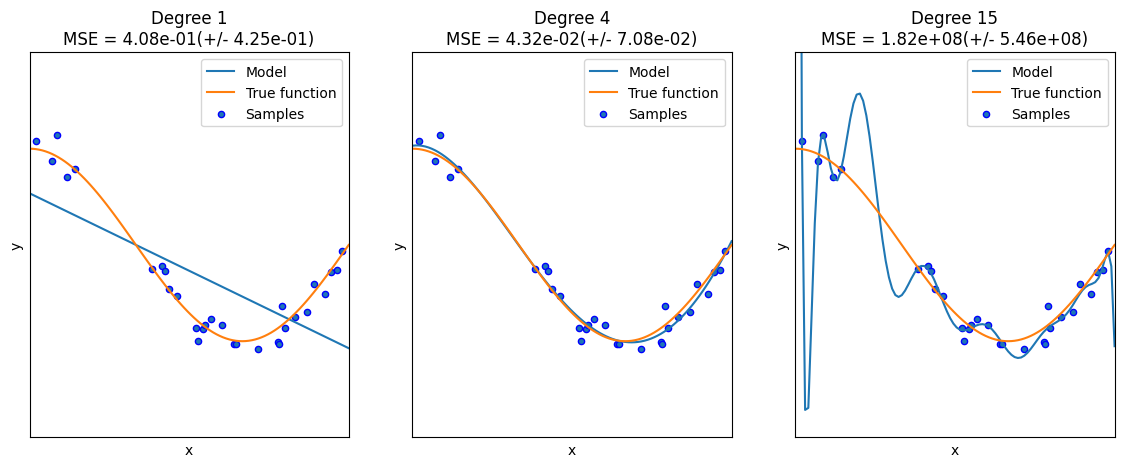

In [27]:
plt.figure(figsize=(14, 5))
for i in range(len(degrees)):
    ax = plt.subplot(1, len(degrees), i + 1)
    plt.setp(ax, xticks=(), yticks=())

    polynomial_features = PolynomialFeatures(degree=degrees[i],
                                             include_bias=False)
    linear_regression = LinearRegression()
    pipeline = Pipeline([("polynomial_features", polynomial_features),
                         ("linear_regression", linear_regression)])
    pipeline.fit(X[:, np.newaxis], y)

    # 使用交叉验证评估模型
    scores = cross_val_score(pipeline, X[:, np.newaxis], y, scoring="neg_mean_squared_error", cv=10)

    X_test = np.linspace(0, 1, 100)
    plt.plot(X_test, pipeline.predict(X_test[:, np.newaxis]), label="Model")
    plt.plot(X_test, true_fun(X_test), label="True function")
    plt.scatter(X, y, edgecolor='b', s=20, label="Samples")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc="best")
    plt.title("Degree {}\nMSE = {:.2e}(+/- {:.2e})".format(degrees[i], -scores.mean(), scores.std()))
plt.show()

<a id="12.-Bias-vs-Variance-trade-off"></a>

## 12. 偏差与方差的权衡（Bias–Variance Trade-off）

下面的图有助于回顾偏差与方差之间的关系。

<img src="bias-vs-variance.png" alt="偏差与方差之间的关系" style="width: 600px;"/>

### 正则化：以引入一定偏差为代价，降低方差

<img src="bias-vs-variance2.png" alt="正则化对偏差与方差的影响" style="width: 600px;"/>


<!-- classroom:bias_variance -->

### 课堂补充｜用前面的岭回归例子理解“方差”

老师在解释岭回归系数路径时，给出了一个具体问题：**稍微改变训练数据，再拟合一次，得到的权重会不会变化很大？** 如果变化很大，就说明估计对这批样本非常敏感。这是课堂用来说明高方差的直观例子。

增强正则化，可以让模型少受某份样本细节的牵动；但约束过强，模型也可能失去描述真实关系所需的灵活性。老师因此提醒，两个极端都不是目标，要在稳定性与表达能力之间寻找合适的平衡。

**整理说明：** 相关问答里关于偏差和方差的几句表述有混淆。这里沿用讲义中一致的含义：偏差关注模型的平均预测与真实关系之间的系统性差异；方差关注训练样本改变时，拟合结果如何波动。不能把“在训练集上答得好”直接定义成高偏差，也不能把“接受所有数据”定义成高方差。

*转录来源：[transcript_part2.md](./transcript_part2.md)，第 154—164 行。*

<!-- /classroom:bias_variance -->



<a id="13.-Validation-techniques"></a>

## 13. 验证方法（Validation Techniques）

交叉验证可用于以下两类情况：

* **A. 模型评估与最佳算法选择。** 假设有 $K$ 个不同的模型可以解决同一个问题，记为 $\text{model}_1,\dots,\text{model}_K$。我们可以使用交叉验证，尽可能*客观地*衡量每个模型的性能，最终找出其中最好的模型。
* **B. 模型选择／校准（Calibration，即调整超参数 Hyperparameters）。** 在这种情况下，我们关注同一种模型在不同超参数配置下的变体。目标同样是确定哪一种参数配置对这个特定模型最好。

容易看出，如果有 $K$ 个候选模型，可以先执行阶段 B，分别为这 $K$ 个模型找到各自的最佳参数配置，然后再比较不同模型，找出最好的那个。


### 训练集与测试集划分（Train-Test Split）

<img src="traintest.png" alt="训练集与测试集划分" style="width: 150px;"/>


<!-- classroom:holdout -->

### 课堂补充｜为什么留出一部分数据不训练？

老师把留出数据比作考试：学习的目标是应对新的问题，不是仅仅记住课堂上出现过的问答。一个识别坏橙子的系统，也不可能在训练时见过以后所有要分拣的橙子。

把一部分数据留到训练结束后才使用，就是在已有数据范围内模拟这种情况：模型需要面对没有参与参数拟合的样本。如果训练和评分都使用同一份数据，就很难发现模型只是记住了样本细节。

**整理说明：** 老师先用交叉验证这个总称引入验证思想，随后才区分单次留出与 K 折。此处这张图具体对应的是训练／测试留出划分。

*转录来源：[transcript_part3.md](./transcript_part3.md)，第 313—324 行。*

<!-- /classroom:holdout -->



### 训练集、验证集（Validation Set）与测试集划分

<img src="traintestvalidation.png" alt="训练集、验证集与测试集划分" style="width: 135px;"/>


<!-- classroom:test_leakage -->

### 课堂补充｜反复看测试分数再调 alpha，也会泄漏信息

即使测试数据没有直接传给 `fit`，如果每次看见测试分数不好，就回去调整 alpha，再训练、再看测试结果，测试集仍然在影响最终模型。老师将其解释为：我们从测试集取出了反馈，再把反馈带回选择过程。

因此，训练集用于拟合权重，验证集用于比较超参数配置，测试集留到这些选择结束后再作最终评估。三者的区别在于用途；仅仅给数组起不同名字，并不能保证测试信息没有进入选择过程。

*转录来源：[transcript_part3.md](./transcript_part3.md)，第 325—333 行。*

<!-- /classroom:test_leakage -->



### 交叉验证

<img src="cv.png" alt="交叉验证的数据划分方式" style="width: 650px;"/>


<!-- classroom:kfold -->

### 课堂补充｜K 折得到的是多个模型的评分，不是同一个模型反复考试

一次随机划分可能恰好容易，也可能恰好困难。老师用五折说明如何减少对一次划分的依赖：把数据分成五组，每次用四组训练、另一组评估，轮流进行，再汇总评分。

关键是，每一折都重新训练，训练数据不同，得到的权重也可能不同。保持一致的是建模方法及配置，而不是某一组已经拟合好的参数。五折平均分是在估计这套方法面对不同划分时的表现，可用来与另一种方法比较。

**课堂问答：最终是不是选得分最高的那一折模型？** 老师回答，不应这样理解。某折比另一折高一点，可能只是划分差异；交叉验证的目的，是帮助我们判断方法或配置是否合适，而不是从几折里挑一个最幸运的模型。

在模型形式与超参数确定后，老师建议用全部可用的开发数据重新拟合最终模型，让更多观测参与参数估计，然后面对实际的新数据。

**整理说明：** 这里的“全部数据”是模型选择完成后的最终拟合阶段。如果还保留一份用于最终独立评估的测试集，那么在完成并报告这次评估之前，仍不能把它混入训练。重新拟合最终模型后，也不能再把已用于拟合的数据评分当成独立测试结果。

*转录来源：[transcript_part3.md](./transcript_part3.md)，第 334—359 行。*

<!-- /classroom:kfold -->



### 嵌套交叉验证

在模型选择中，标准交叉验证可能使用同一批数据来调整模型参数，并最终评估模型性能。这可以视为一种“信息泄漏（Information Leak）”，可能增加模型对现有数据过拟合的风险。也就是说，当模型面对完全未知的数据时，出现较高泛化误差（Generalization Error）的风险会增大。

嵌套交叉验证试图将参数调优与模型评估分离。是否选择它来代替标准交叉验证，取决于可用数据的数量，以及所要解决问题的难度。

可在[这里](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html)查看实际示例。

<img src="nestedcv.png" alt="嵌套交叉验证的内外层划分" style="width: 700px;"/>
